# Data Analysis Basics: Pandas, NumPy & Matplotlib

In [226]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Pandas: Data Exploration

In [227]:
df = pd.read_csv('Salary_Data.csv')
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [228]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist(),"\n")
df.info()

Shape: (6704, 6)

Columns: ['Age', 'Gender', 'Education Level', 'Job Title', 'Years of Experience', 'Salary'] 

<class 'pandas.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   str    
 2   Education Level      6701 non-null   str    
 3   Job Title            6702 non-null   str    
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), str(3)
memory usage: 314.4 KB


In [229]:
df.describe()

,Age,Years of Experience,Salary
count,6702.000000,6701.000000,6699.000000
mean,33.620859,8.094687,115326.964771
std,7.614633,6.059003,52786.183911
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


## 2. Pandas: Data Cleaning

In [230]:
df.isnull().sum()

Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64

In [231]:
df = df.dropna()
df = df.drop_duplicates()
print("Cleaned Shape:", df.shape)

Cleaned Shape: (1787, 6)


In [232]:
df['Education Level'].value_counts()

Education Level
Bachelor's Degree    506
Master's Degree      446
PhD                  340
Bachelor's           262
Master's             122
High School          110
phD                    1
Name: count, dtype: int64

In [233]:
edu_map = {
    "Bachelor's Degree": "Bachelor's",
    "Master's Degree": "Master's",
    "phD": "PhD"
}
df['Education Level'] = df['Education Level'].replace(edu_map)
df['Education Level'].value_counts()

Education Level
Bachelor's     768
Master's       568
PhD            341
High School    110
Name: count, dtype: int64

## 3. Pandas: Filtering, Sorting & Grouping

In [234]:
df.iloc[0:5, 0:3]

,Age,Gender,Education Level
0,32.0,Male,Bachelor's
1,28.0,Female,Master's
2,45.0,Male,PhD
3,36.0,Female,Bachelor's
4,52.0,Male,Master's


In [235]:
df.loc[df['Job Title'] == 'Software Engineer', ['Age', 'Years of Experience', 'Salary']].head()

,Age,Years of Experience,Salary
0,32.0,5.0,90000.0
376,28.0,3.0,125000.0
380,29.0,4.0,140000.0
384,31.0,6.0,155000.0
395,28.0,3.0,125000.0


In [236]:
high_salary_phd = df[(df['Education Level'] == 'PhD') & (df['Salary'] > 150000)]
high_salary_phd.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
34,46.0,Male,PhD,Senior Manager,20.0,170000.0
63,47.0,Male,PhD,Senior Data Scientist,21.0,180000.0
72,45.0,Male,PhD,Research Director,16.0,190000.0
83,52.0,Male,PhD,Chief Technology Officer,24.0,250000.0
96,47.0,Male,PhD,Research Scientist,22.0,160000.0


In [237]:
df.sort_values(by='Salary', ascending=False).head(5)

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
30,50.0,Male,Bachelor's,CEO,25.0,250000.0
83,52.0,Male,PhD,Chief Technology Officer,24.0,250000.0
5001,45.0,Male,Bachelor's,Financial Manager,21.0,250000.0
4276,51.0,Male,PhD,Data Scientist,24.0,240000.0
4397,49.0,Male,Master's,Marketing Manager,23.0,228000.0


In [238]:
df.groupby('Education Level')['Salary'].agg(['count', 'mean', 'median', 'min', 'max'])

,count,mean,median,min,max
Education Level,,,,,
Bachelor's,768,91145.566406,80000.0,350.0,250000.0
High School,110,45435.981818,35000.0,25000.0,166109.0
Master's,568,127432.806338,127131.0,32000.0,228000.0
PhD,341,160942.521994,170000.0,579.0,250000.0


In [239]:
# Exercise 1:
# Filter employees with Age < 30 and Salary > 80000

## 4. NumPy: Arrays & Math Operations

In [240]:
salaries = df['Salary'].to_numpy()
experience = df['Years of Experience'].to_numpy()

print("Shape:", salaries.shape)
print("Data Type:", salaries.dtype)

Shape: (1787,)
Data Type: float64


In [241]:
monthly_salaries = salaries / 12
salaries_with_bonus = salaries * 1.10

print("Monthly (first 5):", np.round(monthly_salaries[:5], 2))
print("With 10% Bonus (first 5):", np.round(salaries_with_bonus[:5], 2))

Monthly (first 5): [ 7500.    5416.67 12500.    5000.   16666.67]
With 10% Bonus (first 5): [ 99000.  71500. 165000.  66000. 220000.]


In [251]:
print("Mean:", np.mean(salaries))
print("Median:", np.median(salaries))
print("Std Dev:", np.std(salaries))
print("Min:", np.min(salaries))
print("Max:", np.max(salaries))

Mean: 113184.65976496923
Median: 110000.0
Std Dev: 51582.09810993667
Min: 350.0
Max: 250000.0


In [256]:
avg_salary = np.mean(salaries)
print(avg_salary)
df['Salary_Level'] = np.where(salaries >= avg_salary, 'High', 'Low')
df[['Salary', 'Salary_Level']].head()

113184.65976496923


,Salary,Salary_Level
0,90000.0,Low
1,65000.0,Low
2,150000.0,High
3,60000.0,Low
4,200000.0,High


In [244]:
# Exercise 2:
# Calculate the 25th, 50th, and 75th percentiles of 'salaries' using np.percentile()

## 5. Matplotlib: Data Visualization

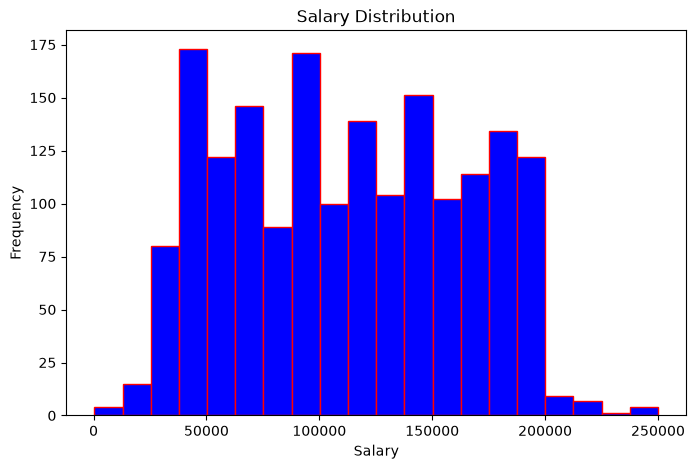

In [260]:
plt.figure(figsize=(8, 5))
plt.hist(df['Salary'], bins=20, color='blue', edgecolor='r')
plt.title('Salary Distribution')
plt.xlabel('Salary')
plt.ylabel('Frequency')
plt.show()

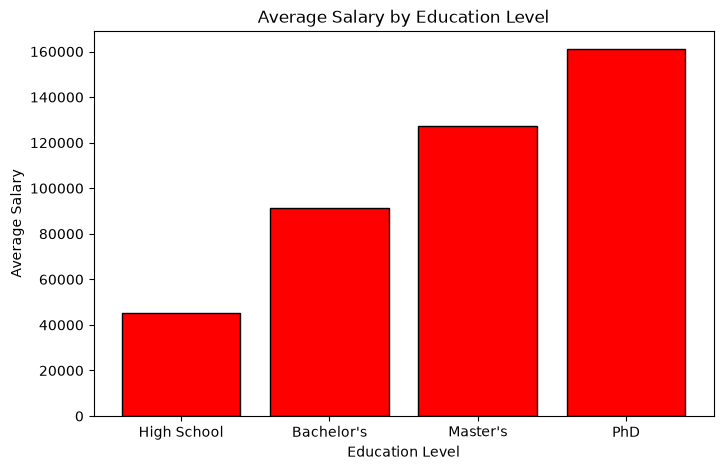

In [261]:
edu_salary = df.groupby('Education Level')['Salary'].mean().sort_values()

plt.figure(figsize=(8, 5))
plt.bar(edu_salary.index, edu_salary.values, color='r', edgecolor='black')
plt.title('Average Salary by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Average Salary')
plt.show()

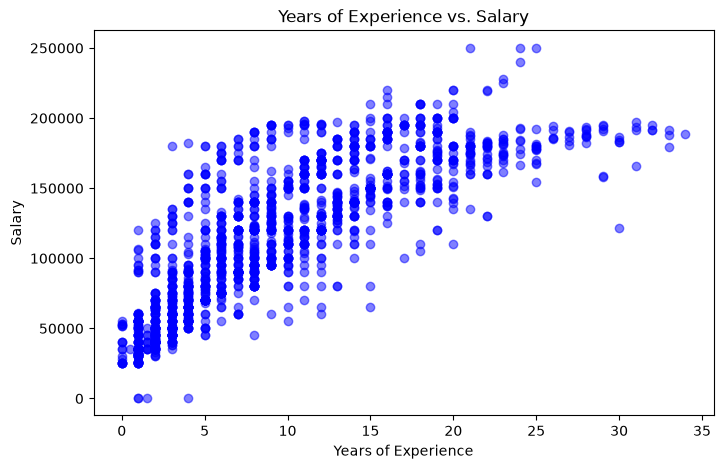

In [262]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Years of Experience'], df['Salary'], alpha=0.5, color='blue')
plt.title('Years of Experience vs. Salary')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.show()

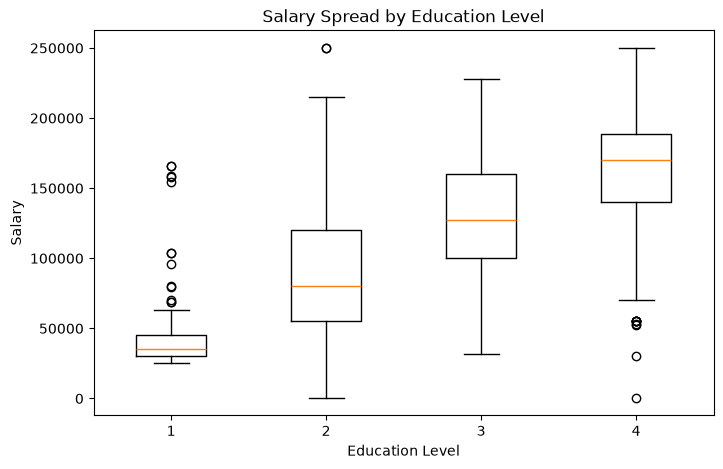

In [248]:
edu_levels = ["High School", "Bachelor's", "Master's", "PhD"]
box_data = [df[df['Education Level'] == level]['Salary'] for level in edu_levels]

plt.figure(figsize=(8, 5))
plt.boxplot(box_data, label=edu_levels)
plt.title('Salary Spread by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Salary')
plt.show()

In [249]:
# Exercise 3:
# Create a bar chart showing the top 5 most common Job Titles